In [40]:
%pip install pypdfium2
import pypdfium2 as pdfium
from IPython.display import Image, display

Note: you may need to restart the kernel to use updated packages.


## Libraries

In [41]:

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.utils import to_categorical


import matplotlib.pyplot as plt
import numpy as np


import seaborn as sns
from sklearn.metrics import confusion_matrix

from tensorflow.keras.callbacks import EarlyStopping

## Dataset Loading & Preprocessing

In [42]:
"""
Image arrays and labels
Keras CNN layers strictly demand a 3D input format
Normalizes Pixels between 0 and 1, prevents gradient explosion
255.0 is the maximum color channel = white
One-hot encodes labels
"""
def preprocess_data(X, y, num_classes = 10):
    X_processed = np.expand_dims(X, -1).astype("float32") / 255.0
    y_processed = tf.keras.utils.to_categorical(y, num_classes)
    return X_processed, y_processed


In [43]:
"""
This is a dataset of 70,000 28x28 grayscale images of the 10 digits, along with a test set of 10,000 images
Load and process data
Presplit data
X_train: uint8 NumPy array of grayscale image data with shapes (60000, 28, 28), containing the training data. Pixel values range from 0 to 255
y_train: uint8 NumPy array of digit labels (integers in range 0-9) with shape (60000,) for the training data
X_test: uint8 NumPy array of grayscale image data with shapes (10000, 28, 28), containing the test data. Pixel values range from 0 to 255
y_test: uint8 NumPy array of digit labels (integers in range 0-9) with shape (10000,) for the test data
"""
(X_tr_data, y_tr_data), (X_te_data, y_te_data) = tf.keras.datasets.mnist.load_data()

X_tr, y_tr = preprocess_data(X_tr_data, y_tr_data, num_classes = 10)
X_te, y_te = preprocess_data(X_te_data, y_te_data, num_classes = 10)

print(f"Preprocessed Train Images Shape: {X_tr.shape}") # Outputs: (60000, 28, 28, 1)
print(f"Preprocessed Train Labels Shape: {y_tr.shape}") # Outputs: (60000, 10)
print(f"Preprocessed Test Images Shape: {X_te.shape}") # Outputs: (10000, 28, 28, 1)
print(f"Preprocessed Test Labels Shape: {y_te.shape}") # Outputs: (10000, 10)


Preprocessed Train Images Shape: (60000, 28, 28, 1)
Preprocessed Train Labels Shape: (60000, 10)
Preprocessed Test Images Shape: (10000, 28, 28, 1)
Preprocessed Test Labels Shape: (10000, 10)


In [44]:
"""
categories
"""
integer_labels = np.argmax(y_te, axis=1)

unique_categories = np.unique(integer_labels)
print(f"Labels: {unique_categories}")


Labels: [0 1 2 3 4 5 6 7 8 9]


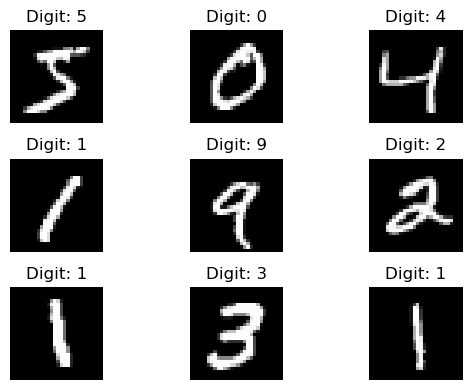

In [45]:
"""
The first 9 images of the training data
"""
plt.figure(figsize = (6,4))

for i in range(9):
    plt.subplot(3, 3, i+1)
    imag_ = X_tr[i].reshape(28,28)
    plt.imshow(imag_, cmap = 'gray')
    digit_label = np.argmax(y_tr[i])
    plt.title(f"Digit: {digit_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## CNN Architecture

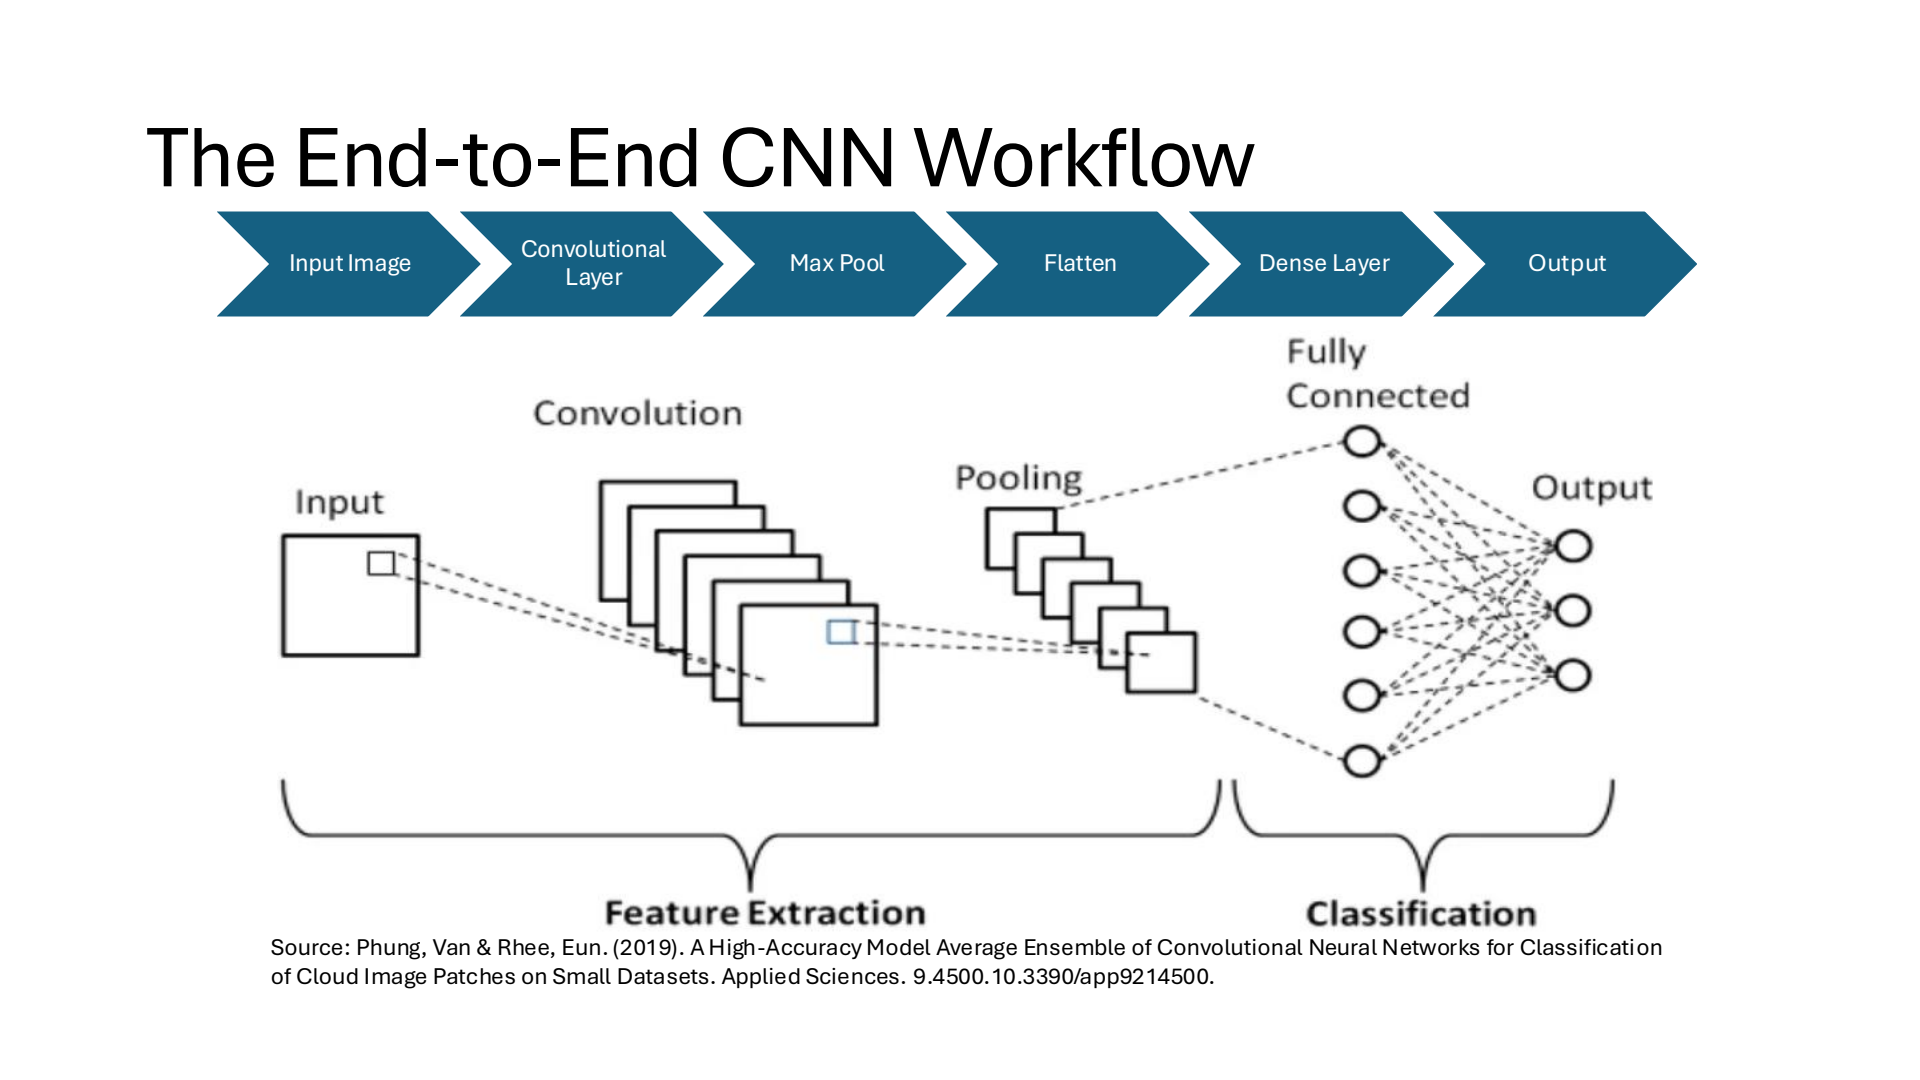

In [46]:
def display_slide(Path_, slide_, width=1300):
    doc = pdfium.PdfDocument(Path_)
    total_slides = len(doc)
    page = doc[slide_ -1]
    
    bitmap = page.render(scale=2)
    pil_img = bitmap.to_pil()
    
    temp_ = f"temp_single_slide.png"
    pil_img.save(temp_)
    

    display(Image(filename=temp_, width=width))

display_slide(r"C:\Users\cathy\CNN.pdf", slide_=5)


In [47]:
"""
Variables
"""
EPOCHS = 10
IMAGE_SIZE = (28, 28)
BATCH_SIZE = 32

In [69]:
"""
CNN architecture
Convolution layers + function
    receptive fields + filters
Pooling
Flatten
"""

def create_cnn_model():
    cnn_ = models.Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 1)),
        # grayscale images (Height, Width, 1)
        
        layers.Conv2D(16, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        
        layers.Dense(10, activation='softmax')
    ])
    """
    models.Sequential(): builds a model as a stack; order matters 
    Applies 16 filters of size (3×3); extract image features
    Reduce feature map size; np.max()
    Flatten layer to convert feature maps into a 1D vector
    Fully connected layer using 32 neurons using ReLu activation
    Fully connected layer using 'softmax'
    """
    cnn_.compile(
        optimizer='sgd',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    """
    Adaptively adjusting learning rates using gradient moments
    Measures loss for multi-class classification tasks
    Tracks model accuracy during training and evaluation
    """
    return cnn_

In [70]:
"""
cnn model
"""

cnn_model = create_cnn_model()

In [71]:
early_stopping = EarlyStopping(
    monitor='val_loss',      # Metric to monitor (usually validation loss)
    patience=5,              # Number of epochs to wait for improvement before stopping
    restore_best_weights=True # Restores model weights from the epoch with the best value
)

## Model Training

In [72]:
"""
Forward pass: 
Processing the local receptive fields
Extracts features through the convolutional process
Prediction for each class
Backward propagation
Calculate gradient~loss
Update Weights: optimizer to minimize loss
"""
EPOCHS_PLUS = EPOCHS+10

# returns a history object
cnn_history = cnn_model.fit(X_tr, 
                        y_tr, 
                        epochs= EPOCHS_PLUS, 
                        batch_size = BATCH_SIZE, 
                        validation_data=(X_te, y_te))

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.7975 - loss: 0.6510 - val_accuracy: 0.9335 - val_loss: 0.2349
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9519 - loss: 0.1607 - val_accuracy: 0.9614 - val_loss: 0.1210
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.9666 - loss: 0.1113 - val_accuracy: 0.9738 - val_loss: 0.0817
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9726 - loss: 0.0897 - val_accuracy: 0.9715 - val_loss: 0.0875
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9763 - loss: 0.0772 - val_accuracy: 0.9804 - val_loss: 0.0609
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9792 - loss: 0.0688 - val_accuracy: 0.9841 - val_loss: 0.0548
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.9812 - loss: 0.0620 - val_accuracy: 0.9822 - val_loss: 0.0585
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9826 -

In [73]:
print(cnn_history.history['val_accuracy'])

[0.9334999918937683, 0.9613999724388123, 0.973800003528595, 0.9714999794960022, 0.980400025844574, 0.9840999841690063, 0.982200026512146, 0.9851999878883362, 0.9829999804496765, 0.9858999848365784, 0.9853000044822693, 0.9840999841690063, 0.9854000210762024, 0.9847000241279602, 0.986299991607666, 0.9878000020980835, 0.9872999787330627, 0.9882000088691711, 0.9868000149726868, 0.9864000082015991]


In [74]:
te_loss, te_acc = cnn_model.evaluate(X_te, y_te)
print(f"Test loss: {te_loss * 100:.2f}%")
print(f"Test accuracy: {te_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9864 - loss: 0.0416
Test loss: 4.16%
Test accuracy: 98.64%


## Model Evaluation

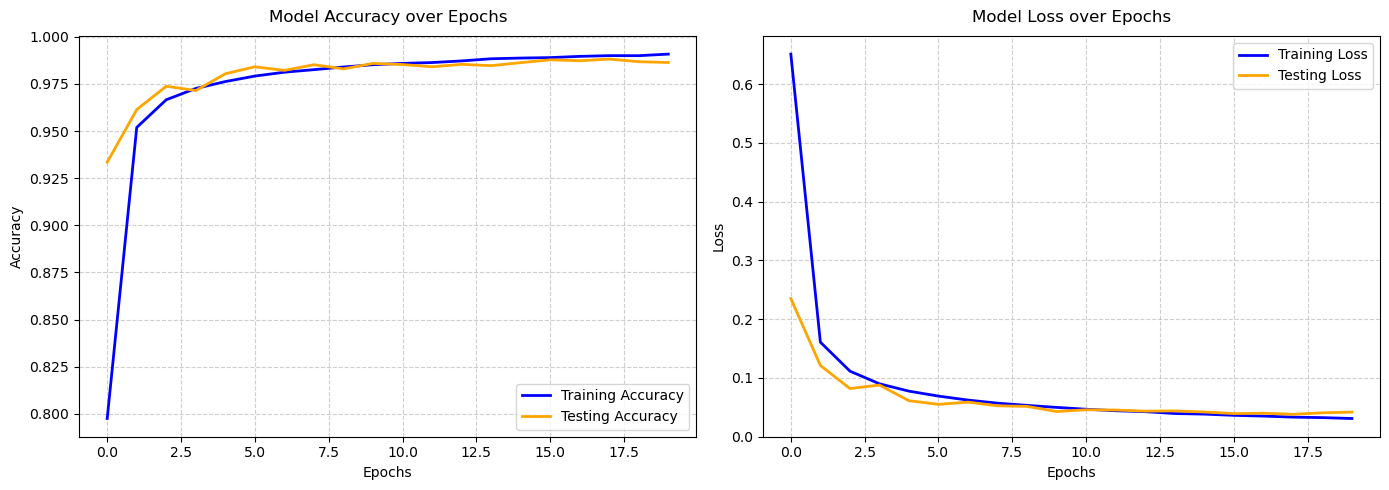

In [75]:

plt.figure(figsize=(14, 5))

# Accuracy across epochs
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], 
         label='Training Accuracy', 
         color='blue', 
         lw=2)
plt.plot(cnn_history.history['val_accuracy'], 
         label='Testing Accuracy', 
         color='orange', 
         lw=2)
plt.title('Model Accuracy over Epochs', 
          fontsize=12, 
          pad=10)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, 
         linestyle='--', 
         alpha=0.6)

# Loss Evaluation
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], 
         label='Training Loss', 
         color='blue', 
         lw=2)
plt.plot(cnn_history.history['val_loss'], 
         label='Testing Loss', 
         color='orange', 
         lw=2)
plt.title('Model Loss over Epochs', 
          fontsize=12, 
          pad=10)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, 
         linestyle='--', 
         alpha=0.6)

plt.tight_layout()
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


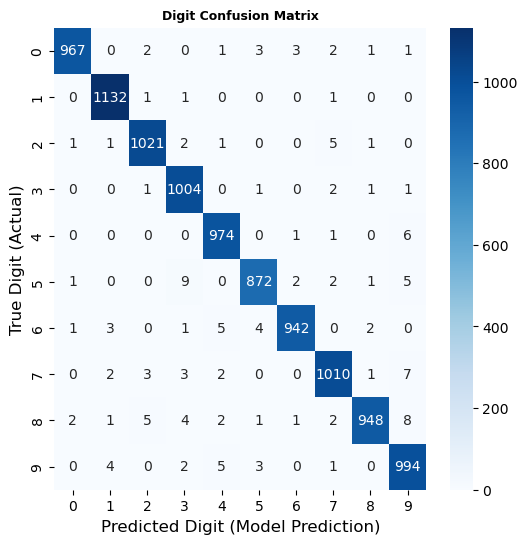

In [76]:
y_pred_probs = cnn_model.predict(X_te)

y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_te, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 6))
sns.heatmap(
    cm, 
    annot=True,          
    fmt='d',             
    cmap='Blues',        
    xticklabels=list(range(10)), 
    yticklabels=list(range(10))
)

plt.title('Digit Confusion Matrix', 
          fontsize=9, 
          weight = "bold")
plt.ylabel('True Digit (Actual)', 
           fontsize=12)
plt.xlabel('Predicted Digit (Model Prediction)', 
           fontsize=12)
plt.show()


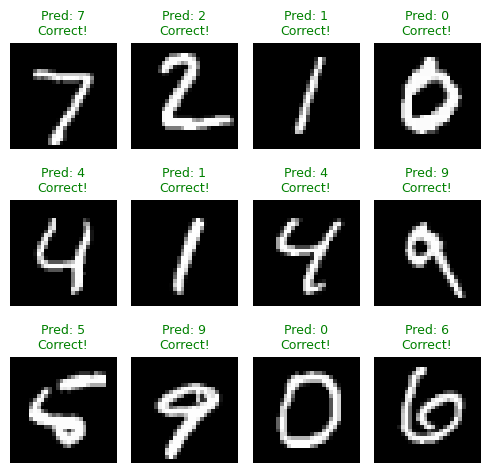

In [77]:
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_te, axis=1)

first_12 = np.arange(12)

fig, axes = plt.subplots(3, 4, figsize=(5, 5))
axes = axes.ravel()

for i, idx in enumerate(first_12):
    img = X_te[idx].reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].axis('off')    
    actual = y_true[idx]
    predicted = y_pred[idx]    
    if actual == predicted:
        color = 'green'
        text = f"Pred: {predicted}\nCorrect!"
    else:
        color = 'red'
        text = f"Pred: {predicted}\nTrue: {actual}"       
    axes[i].set_title(text, color= color, fontsize=9)

plt.tight_layout()
plt.show()
